# Assignment 11: Feature Engineering on the Titanic Dataset

Starting from a raw dataset: handle missing values, encode categorical variables, create at least three new features, remove irrelevant features, and explain how each transformation could improve model performance.

The classwork used the Airlines Delay dataset. Here I use the **Titanic passenger dataset** (891 passengers, predict `survived`) because it is genuinely messy: it has missing ages, missing ports, a mostly-empty `deck` column, text categories, duplicate columns, and even a column that leaks the answer. That makes every step of the assignment meaningful.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Load the Raw Dataset

Seaborn ships the Titanic data as a CSV (downloaded from seaborn's GitHub). Nothing has been cleaned yet.

In [2]:
df = sns.load_dataset("titanic")

print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


## Split Before Engineering

Same idea as the classwork's `fit_transform` on train and `transform` on test: any value I *learn* from the data (a median age, the most common port, the list of categories) must come from the training set only. Otherwise information from the test set leaks into training and the test score looks better than it really is. So I split first and every step below learns from `train` and applies the same rule to `test`.

In [4]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["survived"])
train, test = train.copy(), test.copy()

print("Train:", train.shape, " Test:", test.shape)

Train: (712, 15)  Test: (179, 15)


## 1. Handle Missing Values

In [5]:
missing = pd.DataFrame({
    "Missing (train)": train.isna().sum(),
    "Missing %": (train.isna().mean() * 100).round(1),
})
missing[missing["Missing (train)"] > 0].sort_values("Missing %", ascending=False)

,Missing (train),Missing %
deck,553,77.7
age,137,19.2
embarked,2,0.3
embark_town,2,0.3


Three columns need attention, and each one gets a different strategy because each is missing for a different reason:

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `deck` | ~77% | Fill with a new category `"Unknown"` | Too empty to impute, but *whether* a deck was recorded is informative (deck records mostly exist for 1st-class cabins). |
| `age` | ~20% | Median age **per sex + passenger class** group, plus an `age_was_missing` flag | A 1st-class woman and a 3rd-class man have very different typical ages, so a group median is more accurate than one global median. The flag lets the model learn if "age unknown" itself matters. |
| `embarked` / `embark_town` | 2 rows | Most frequent port | Only 2 rows; the mode is the safest guess and dropping rows would waste data. |

In [6]:
# Learn the fill values from TRAIN only
age_medians = train.groupby(["sex", "pclass"])["age"].median()
embarked_mode = train["embarked"].mode()[0]
embark_town_mode = train["embark_town"].mode()[0]

print("Median age by sex and class (learned from train):")
print(age_medians)
print("\nMost common port:", embarked_mode, "/", embark_town_mode)

Median age by sex and class (learned from train):
sex     pclass
female  1         35.0
        2         29.0
        3         21.5
male    1         40.0
        2         30.0
        3         26.0
Name: age, dtype: float64

Most common port: S / Southampton


In [7]:
def handle_missing(data):
    data = data.copy()
    data["age_was_missing"] = data["age"].isna().astype(int)
    data["age"] = data.apply(
        lambda row: age_medians[(row["sex"], row["pclass"])] if pd.isna(row["age"]) else row["age"],
        axis=1,
    )
    data["embarked"] = data["embarked"].fillna(embarked_mode)
    data["embark_town"] = data["embark_town"].fillna(embark_town_mode)
    data["deck"] = data["deck"].astype(object).fillna("Unknown")
    return data

train = handle_missing(train)
test = handle_missing(test)

print("Missing values left (train):", train.isna().sum().sum())
print("Missing values left (test): ", test.isna().sum().sum())

Missing values left (train): 0
Missing values left (test):  0


## 2. Encode Categorical Variables

Models only understand numbers. Each text column gets the encoding that matches what kind of category it is:

- **`sex`** has two values, so a single 0/1 column (`is_female`) is enough.
- **`embarked`** (S/C/Q) and **`deck`** (A–G/Unknown) are *nominal*: no order between them, so they get **one-hot encoding** like the classwork's `OneHotEncoder`. Giving them numbers 1, 2, 3 would wrongly tell the model that Q > C > S.
- **`pclass`** is already numeric and genuinely *ordinal* (1st > 2nd > 3rd), so it stays as is.

In [8]:
def encode(data):
    data = data.copy()
    data["is_female"] = (data["sex"] == "female").astype(int)
    data = pd.get_dummies(data, columns=["embarked", "deck"], prefix=["embarked", "deck"], dtype=int)
    return data

train = encode(train)
test = encode(test)

# A deck that never shows up in test would leave test with fewer columns,
# so line test up with exactly the columns learned on train (missing ones become 0)
test = test.reindex(columns=train.columns, fill_value=0)

print("Columns after encoding:", train.shape[1])
train.filter(regex="is_female|embarked_|deck_").head()

Columns after encoding: 26


,is_female,embarked_C,embarked_Q,embarked_S,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_Unknown
692,0,0,0,1,0,0,0,0,0,0,0,1
481,0,0,0,1,0,0,0,0,0,0,0,1
527,0,0,0,1,0,0,1,0,0,0,0,0
855,1,0,0,1,0,0,0,0,0,0,0,1
801,1,0,0,1,0,0,0,0,0,0,0,1


## 3. Create New Features

Four new features, each based on a known pattern in how the evacuation actually worked:

1. **`family_size`** = `sibsp` + `parch` + 1: the number of relatives aboard plus the passenger. Separately, siblings and parents are weak signals; combined they describe the travelling group.
2. **`fare_per_person`** = `fare` / `family_size`: `fare` is the price of the whole *ticket*, which was often shared by a family. Dividing gives a fairer measure of how much each person paid, i.e. their wealth.
3. **`is_child`** = age under 16: "women and children first" means children were prioritized, which a straight-line age effect can't capture well.
4. **`female_in_upper_class`** = female **and** 1st/2nd class: an *interaction* feature. Women in 1st and 2nd class survived at very high rates, while women in 3rd class did much worse. A linear model can't learn "sex matters *differently* depending on class" on its own; this column hands it that combination directly.

(`age_was_missing` from step 1 is also a new feature.)

In [9]:
def create_features(data):
    data = data.copy()
    data["family_size"] = data["sibsp"] + data["parch"] + 1
    data["fare_per_person"] = data["fare"] / data["family_size"]
    data["is_child"] = (data["age"] < 16).astype(int)
    data["female_in_upper_class"] = ((data["is_female"] == 1) & (data["pclass"] <= 2)).astype(int)
    return data

train = create_features(train)
test = create_features(test)

new_features = ["family_size", "fare_per_person", "is_child", "female_in_upper_class", "age_was_missing"]
train[new_features].describe().round(2)

,family_size,fare_per_person,is_child,female_in_upper_class,age_was_missing
count,712.00,712.00,712.00,712.00,712.00
mean,1.88,20.40,0.09,0.19,0.19
std,1.59,37.72,0.29,0.39,0.39
min,1.00,0.00,0.00,0.00,0.00
25%,1.00,7.25,0.00,0.00,0.00
50%,1.00,8.45,0.00,0.00,0.00
75%,2.00,20.48,0.00,0.00,0.00
max,11.00,512.33,1.00,1.00,1.00


Quick check that the new features actually relate to survival (training data only):

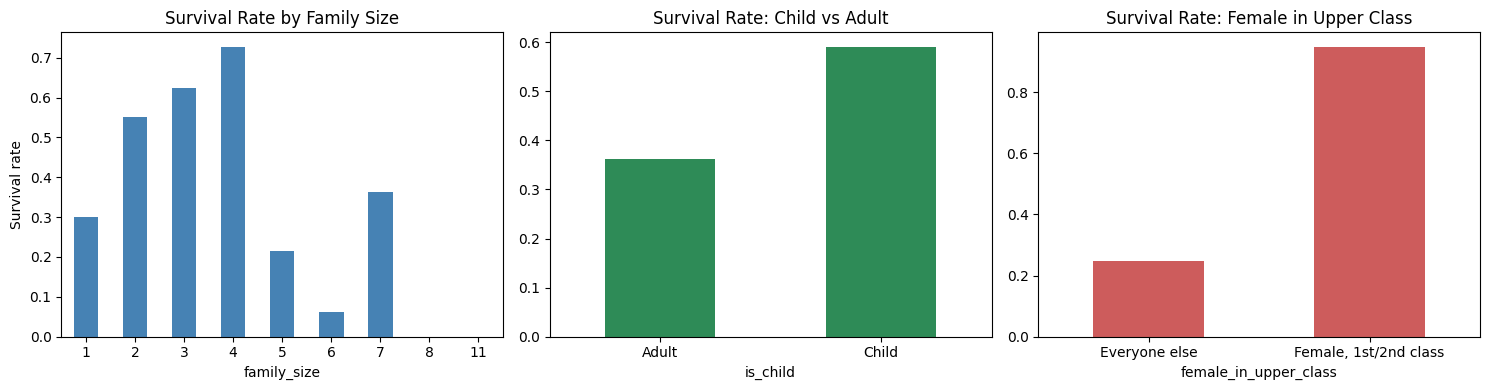

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

train.groupby("family_size")["survived"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Survival Rate by Family Size")
axes[0].set_ylabel("Survival rate")

train.groupby("is_child")["survived"].mean().rename({0: "Adult", 1: "Child"}).plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Survival Rate: Child vs Adult")

train.groupby("female_in_upper_class")["survived"].mean().rename({0: "Everyone else", 1: "Female, 1st/2nd class"}).plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("Survival Rate: Female in Upper Class")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

The patterns are clear: people travelling alone (size 1) and in very large families (5+) survived less than those in small families of 2–4, children survived more than adults, and women in 1st/2nd class survived at a far higher rate than everyone else. The relationship with family size is **not a straight line** (it goes up then down), which is something the raw `sibsp`/`parch` columns couldn't show.

## 4. Remove Irrelevant Features

Not every column should go into the model:

| Column(s) | Reason for removal |
|---|---|
| `alive` | **Target leakage**: it's just `survived` written as yes/no. A model with it would score ~100% in testing and be useless in reality, because you'd never know this before predicting. |
| `class` | Exact duplicate of `pclass` (First/Second/Third vs 1/2/3). |
| `embark_town` | Exact duplicate of `embarked` (Southampton = S, etc.). |
| `who`, `adult_male` | Pre-made features derived from `sex` + `age`; now covered by `is_female` and `is_child`. |
| `alone` | Same information as `family_size == 1`. |
| `sex` | Original text column, replaced by `is_female`. |
| `sibsp`, `parch` | Folded into `family_size`. |

In [11]:
drop_cols = ["alive", "class", "embark_town", "who", "adult_male", "alone", "sex", "sibsp", "parch"]

# Proof that 'alive' is just the target in disguise
print("'alive' matches 'survived' in", ((train["alive"] == "yes").astype(int) == train["survived"]).mean() * 100, "% of rows")

X_train = train.drop(columns=drop_cols + ["survived"])
y_train = train["survived"]
X_test = test.drop(columns=drop_cols + ["survived"])
y_test = test["survived"]

print("\nFinal feature count:", X_train.shape[1])
print(list(X_train.columns))

'alive' matches 'survived' in 100.0 % of rows

Final feature count: 20
['pclass', 'age', 'fare', 'age_was_missing', 'is_female', 'embarked_C', 'embarked_Q', 'embarked_S', 'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_Unknown', 'family_size', 'fare_per_person', 'is_child', 'female_in_upper_class']


Finally, a quick correlation check between the remaining numeric features, to make sure I haven't kept any near-duplicates:

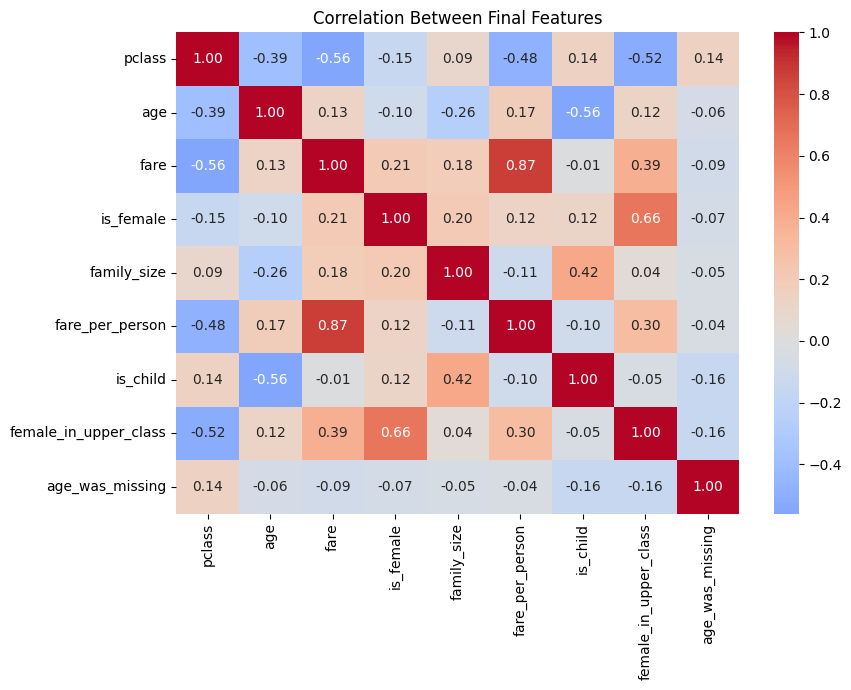

In [12]:
core = ["pclass", "age", "fare", "is_female", "family_size", "fare_per_person", "is_child", "female_in_upper_class", "age_was_missing"]

plt.figure(figsize=(9, 7))
sns.heatmap(X_train[core].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Final Features")
plt.tight_layout()
plt.show()

`fare` and `fare_per_person` are strongly related (as expected), but not identical: two passengers with the same ticket price can be one rich person or a family of six. No pair is a straight duplicate, so I keep them all.

## Does Feature Engineering Actually Help?

To see the effect, I compare two versions with the same models:

- **Baseline (minimal cleaning):** only the columns that were already numeric (`pclass`, `age`, `sibsp`, `parch`, `fare`), with missing ages filled by one global median. No categories, no new features.
- **Engineered:** the full feature set built above.

I report 5-fold cross-validated accuracy on the training set (more stable than one split) and the accuracy on the held-out test set.

In [13]:
base_cols = ["pclass", "age", "sibsp", "parch", "fare"]
raw_train, raw_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["survived"])
global_median = raw_train["age"].median()
Xb_train = raw_train[base_cols].fillna({"age": global_median})
Xb_test = raw_test[base_cols].fillna({"age": global_median})

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
}

rows = []
for name, model in models.items():
    for version, (Xtr, Xte) in {"Baseline": (Xb_train, Xb_test), "Engineered": (X_train, X_test)}.items():
        cv = cross_val_score(model, Xtr, y_train, cv=5, scoring="accuracy").mean()
        model.fit(Xtr, y_train)
        test_acc = accuracy_score(y_test, model.predict(Xte))
        rows.append({"Model": name, "Features": version, "n_features": Xtr.shape[1],
                     "CV Accuracy": round(cv, 4), "Test Accuracy": round(test_acc, 4)})

results = pd.DataFrame(rows)
results

,Model,Features,n_features,CV Accuracy,Test Accuracy
0,Logistic Regression,Baseline,5,0.7149,0.6760
1,Logistic Regression,Engineered,20,0.8147,0.7877
2,Random Forest,Baseline,5,0.7599,0.6983
3,Random Forest,Engineered,20,0.8274,0.7765


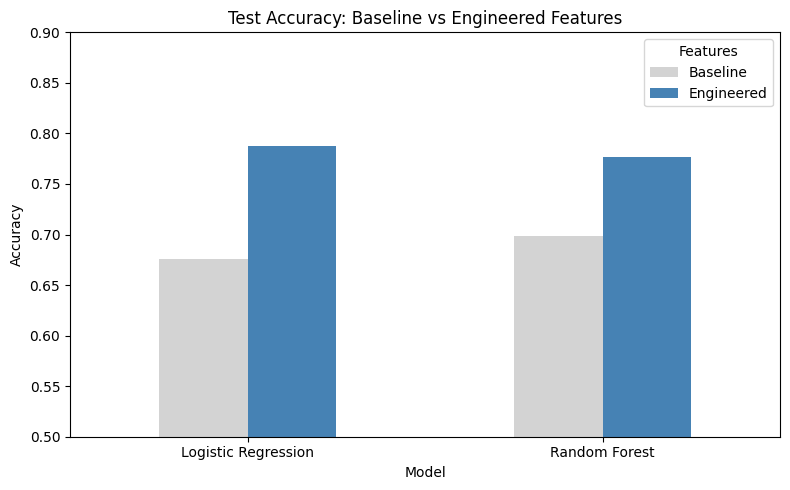

In [14]:
results.pivot(index="Model", columns="Features", values="Test Accuracy").plot(kind="bar", figsize=(8, 5), color=["lightgray", "steelblue"])
plt.title("Test Accuracy: Baseline vs Engineered Features")
plt.ylabel("Accuracy")
plt.ylim(0.5, 0.9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

And the leakage check: what happens if `alive` is accidentally left in?

In [15]:
X_leak_train = X_train.assign(alive=(train["alive"] == "yes").astype(int))
X_leak_test = X_test.assign(alive=(test["alive"] == "yes").astype(int))

leaky = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42).fit(X_leak_train, y_train)
print("Test accuracy WITH the leaky 'alive' column:", accuracy_score(y_test, leaky.predict(X_leak_test)))

Test accuracy WITH the leaky 'alive' column: 1.0


A "perfect" score that would collapse the moment the model is used on real passengers, whose survival isn't known yet. This is why removing that column is the most important removal of all.

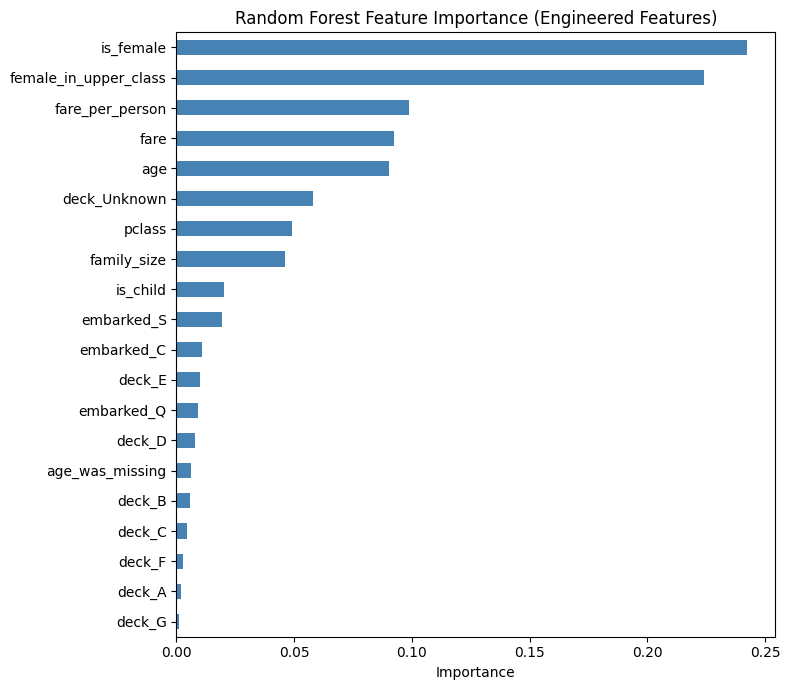

In [16]:
importances = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 7))
importances.plot(kind="barh", color="steelblue")
plt.title("Random Forest Feature Importance (Engineered Features)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## How Each Transformation Could Improve Model Performance

**Measured effect on this dataset:**

| Model | Baseline CV → Engineered CV | Baseline Test → Engineered Test |
|---|---|---|
| Logistic Regression | 71.5% → 81.5% | 67.6% → 78.8% |
| Random Forest | 76.0% → 82.7% | 69.8% → 77.7% |

Both models gain roughly 7–11 accuracy points from the engineered features. Logistic Regression gains the most, because a linear model can't discover interactions or thresholds by itself; the engineered features hand those to it. The feature importance chart confirms that `is_female`, `female_in_upper_class`, `fare_per_person`, `age` and `pclass` are carrying the model.

**Why each transformation helps:**

| Transformation | How it can improve the model |
|---|---|
| **Group-median age imputation** | Keeps all 891 passengers instead of dropping the 20% with no age (more training data). Filling with the median for that sex + class gives a realistic age instead of pulling everyone toward one global value, so the age signal stays sharp. |
| **`age_was_missing` flag** | Imputation hides the fact that a value was missing. The flag keeps that fact, so if "no recorded age" is tied to survival (e.g. lower-class passengers had fewer records) the model can still use it. |
| **Mode for `embarked`, "Unknown" for `deck`** | No rows are lost. Treating a missing deck as its own category turns a 77%-empty column into a useful signal, since recorded decks are mostly 1st-class cabins (in the training data, 70% of passengers with a recorded deck survived vs 29% without). |
| **Binary encoding of `sex`** | Makes the strongest predictor in the dataset usable at all; models can't read the text "female". |
| **One-hot encoding of `embarked` and `deck`** | Lets the model learn a separate effect for each port/deck without making up a false order (S < C < Q). This matters most for linear models, which would otherwise fit a meaningless straight line through arbitrary codes. |
| **`family_size`** | Turns two weak, overlapping columns into one meaningful quantity. Its relationship with survival goes up then down (alone and large families did worse), which tree models pick up easily. |
| **`fare_per_person`** | Corrects a misleading raw value: a shared family ticket looked "expensive" even for poorer passengers. Per-person fare is a cleaner measure of wealth and status, which strongly predicted survival. |
| **`is_child`** | Captures the "children first" rule as a clear threshold. A linear model can only say "older = slightly less likely"; this flag lets it learn the sharp jump for children. |
| **`female_in_upper_class`** | Gives a linear model an interaction it can't create by itself (sex matters more in upper classes). This is where Logistic Regression gains the most. |
| **Removing `alive`** | Prevents target leakage. Without this the test score is a fake 100%, and the model would fail in real use. |
| **Removing duplicates (`class`, `embark_town`, `who`, `adult_male`, `alone`, `sibsp`, `parch`)** | Duplicated information adds no new signal, but it can split importance between copies, make linear model coefficients unstable (multicollinearity), and add noise that leads to overfitting. Fewer, cleaner features also train faster and are easier to interpret. |

**Takeaway:** the biggest gains come from encoding `sex` (the strongest single signal) and from features that put domain knowledge into the data (fare per person, children first, class-dependent sex effect). Removing the leaky column doesn't raise the score, but it's what makes the score honest.